# Comparative Analysis of Machine Learning and Deep Learning Techniques for Handwritten Digit Recognition

## Stage 1: Data Collection and Exploration

### Introduction
Handwritten digits differ in shape, size and writing style. This project uses Python and the labelled MNIST dataset to investigate how a computer can learn to recognise digits from 0 to 9. The complete project will compare a Scikit-learn Logistic Regression classifier with a simple TensorFlow/Keras neural network, using measured results rather than assuming which model will perform better.

Data Science combines programming, statistics and data analysis to answer questions with evidence. Artificial Intelligence is the broader field of intelligent computer systems; Machine Learning learns patterns from examples. Neural networks are one approach to Machine Learning. This is a supervised classification task because each training image has a known digit label.

### Aim
To develop and compare Machine Learning and Deep Learning models for handwritten digit recognition using Python and MNIST.

### Project objectives
- Explore and visualise the images, labels and digit distribution.
- Use introductory statistics to describe the training data.
- Prepare suitable numerical inputs for classification in a later stage.
- Later, train Logistic Regression and a simple neural network, experiment using validation data, and compare their final evaluation results.
- Explain the methods and produce reproducible documentation, a presentation and a prediction demonstration.

### Problem statement
Different people write the same digit in different ways, and some handwritten shapes resemble other digits. The project investigates whether models can learn from labelled numerical images to recognise these classes, and what strengths and limitations each approach has.

**Source:** `Data Science Project.pdf`, pages 1-4. This notebook currently implements Stage 1 only.

## Scope and data separation
The official dataset contains 60,000 training images and 10,000 images reserved for final testing. Each image is a 28 by 28 grayscale array.

The required loader returns both partitions, but all exploration, tables, statistics and plots below use **only `x_train` and `y_train`**. We do not inspect the test images or labels, tune models, scale the modelling arrays, create a validation split, or train a model in Stage 1.

Open this notebook from the project folder and select the `mnist_project` environment. The first code cell checks the interpreter so that the Anaconda base environment is not used accidentally.

## 1. Environment and library imports
Select the `mnist_project` environment, restart the Jupyter kernel, and run all cells from the beginning. The portable setup checks Python 3.11 and the repository working directory, then sets `KERAS_HOME` to `./.keras` **before TensorFlow/Keras is imported**. It checks that the existing `.keras/datasets/mnist.npz` file is present. This keeps the required loader on the local dataset cache. Matplotlib caches are also kept in the project.

These environment and file checks are practical additions for this computer, rather than classroom modelling techniques. No package installation is performed. Select the documented kernel; its executable location may differ between installations.

The analysis imports follow the familiar `pd`, `np`, `plt`, `seaborn` and `tf` aliases. Unused Statsmodels and model-training imports are omitted. We record versions and a seed for reproducibility; Stage 1 uses fixed sample indices and does not make random selections.

**Classroom patterns:** `Bank_Logistic_Regression.ipynb`, cell 1; `linear regression.ipynb`, cell 1; `Untitled19.ipynb`, cell 1. Setting a reproducible seed is an explicit addition to these lesson patterns.

In [1]:
import os
import sys
import importlib.metadata

assert sys.version_info[:2] == (3, 11), 'Select the documented Python 3.11 kernel.'
project_dir = os.path.abspath(os.getcwd())
assert os.path.isfile(os.path.join(project_dir, 'MNIST_Final_Project.ipynb')), 'Open the notebook from the repository root.'

keras_home = os.path.join(project_dir, '.keras')
os.environ['KERAS_HOME'] = keras_home
os.environ['MPLCONFIGDIR'] = os.path.join(os.getcwd(), '.cache', 'matplotlib')
dataset_path = os.path.join(keras_home, 'datasets', 'mnist.npz')
assert os.path.isfile(dataset_path), 'The local MNIST cache is missing. Restore mnist.npz before running the notebook.'

print('Python executable:', sys.executable)
print('Python version:', sys.version.split()[0])
print('KERAS_HOME:', os.environ['KERAS_HOME'])
print('Local MNIST cache:', dataset_path)

Python executable: <active Python interpreter>
Python version: 3.11.17
KERAS_HOME: ./.keras
Local MNIST cache: ./.keras/datasets/mnist.npz


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn
import tensorflow as tf

seaborn.set()
np.random.seed(42)

for package_name in ['tensorflow', 'keras', 'numpy', 'pandas', 'matplotlib', 'seaborn']:
    print(package_name + ': ' + importlib.metadata.version(package_name))
print('NumPy seed: 42; no random sampling is used in Stage 1.')

tensorflow: 2.21.0
keras: 3.15.1
numpy: 2.4.6
pandas: 3.1.0
matplotlib: 3.11.2
seaborn: 0.13.2
NumPy seed: 42; no random sampling is used in Stage 1.


## 2. Load the MNIST dataset from the local cache
MNIST is loaded directly through `tf.keras.datasets.mnist.load_data()`, exactly as required by the project brief. The setup above points Keras to the existing local file `.keras/datasets/mnist.npz`; no manual image loading or alternative dataset is used. Keras verifies the cached dataset against its expected hash.

During verification, the execution helper blocks network requests and records local dataset-file reads. This check is separate from the simple classroom analysis code. The notebook records the verified cache hash and offline execution status in its metadata.

**Required adaptation:** `Untitled19.ipynb`, cell 1, uses `tensorflow_datasets`. Here we use the Keras loader specified in the PDF, page 2. The labels remain the supplied integers; no binary yes/no mapping is needed.

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print('MNIST loaded. The official test partition is reserved for final evaluation.')

MNIST loaded. The official test partition is reserved for final evaluation.


## 3. Inspect the training data structure
The first dimension counts images. The other two dimensions describe the height and width of each image. `y_train` contains one categorical digit label per training image.

**Classroom patterns:** `Untitled13.ipynb`, cells 8-17, inspects types, shapes and reshaping. The `ndim`, `dtype` and `nbytes` attributes extend that inspection to image dimensions, numerical storage and memory use.

In [4]:
print('Training image array type:', type(x_train))
print('Training image shape:', x_train.shape)
print('Training label shape:', y_train.shape)
print('Image array dimensions:', x_train.ndim)
print('One image shape:', x_train[0].shape)
print('Pixels per image:', x_train.shape[1] * x_train.shape[2])
print('Image data type:', x_train.dtype)
print('Label data type:', y_train.dtype)
print('Training image storage (MiB): {0:.2f}'.format(x_train.nbytes / 1024**2))

Training image array type: <class 'numpy.ndarray'>
Training image shape: (60000, 28, 28)
Training label shape: (60000,)
Image array dimensions: 3
One image shape: (28, 28)
Pixels per image: 784
Image data type: uint8
Label data type: uint8
Training image storage (MiB): 44.86


### Observations: training structure
The executed output shows **60,000 training images**, each **28 by 28 pixels** (**784 pixels per image**). The training image array is three-dimensional, with shape `(60000, 28, 28)`; the label array has shape `(60000,)`.

Both arrays use `uint8` storage. The original training image array occupies **44.86 MiB**, excluding interpreter/framework overhead and temporary calculations. Keeping it as uint8 avoids retaining a floating-point copy during exploration. No modelling reshaping or normalization has been applied.

## 4. Inspect numerical pixels and labels
A pixel intensity of 0 represents black, and 255 represents white. Intermediate values represent shades of gray. We inspect an 8 by 8 patch from the first training image to see the numerical representation without printing the entire dataset.

Digit labels identify categories. Although the labels are stored as numbers, calculating their mean would not describe an average handwritten digit.

**Classroom patterns:** `Untitled20.ipynb`, cell 2, uses NumPy slicing to select data; `Untitled13.ipynb`, cells 4-17, inspects arrays. `np.unique`, and pixel minimum/maximum checks, are simple additions needed for image exploration.

In [5]:
print('Small pixel patch from the first training image:')
print(x_train[0, 10:18, 10:18])
print('Minimum training pixel value:', x_train.min())
print('Maximum training pixel value:', x_train.max())
print('First training label:', y_train[0])
print('First 20 training labels:', y_train[:20])
print('Distinct training labels:', np.unique(y_train))

Small pixel patch from the first training image:
[[  1 154 253  90   0   0   0   0]
 [  0 139 253 190   2   0   0   0]
 [  0  11 190 253  70   0   0   0]
 [  0   0  35 241 225 160 108   1]
 [  0   0   0  81 240 253 253 119]
 [  0   0   0   0  45 186 253 253]
 [  0   0   0   0   0  16  93 252]
 [  0   0   0   0   0   0   0 249]]
Minimum training pixel value: 0
Maximum training pixel value: 255
First training label: 5
First 20 training labels: [5 0 4 1 9 2 1 3 1 4 3 5 3 6 1 7 2 8 6 9]
Distinct training labels: [0 1 2 3 4 5 6 7 8 9]


## 5. Display sample handwritten digits
The image is displayed beside its supplied label. A fixed grayscale range of 0-255 gives all sample images a consistent intensity scale.

**Required visualization addition:** `plt.imshow`, grayscale display and hiding image axes follow the sample code in `Data Science Project.pdf`, page 2. Figure labels and `plt.show()` follow `linear regression.ipynb`, cell 6.

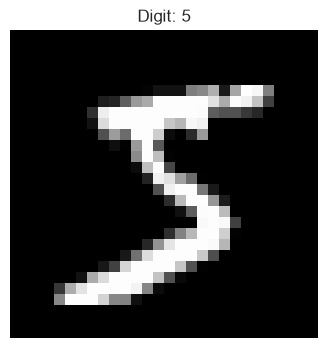

In [6]:
plt.figure(figsize=(4, 4))
plt.imshow(x_train[0], cmap='gray', vmin=0, vmax=255)
plt.title('Digit: ' + str(y_train[0]))
plt.axis('off')
plt.show()

The following grid displays the first 20 training images in their original order. It illustrates individual examples; it is not a random or representative sample of the complete dataset.

**Classroom pattern and extension:** the `for`/`range` loop follows `Untitled10.ipynb`, cell 12. `plt.subplot` and `plt.tight_layout` are small additions to arrange the required image examples clearly.

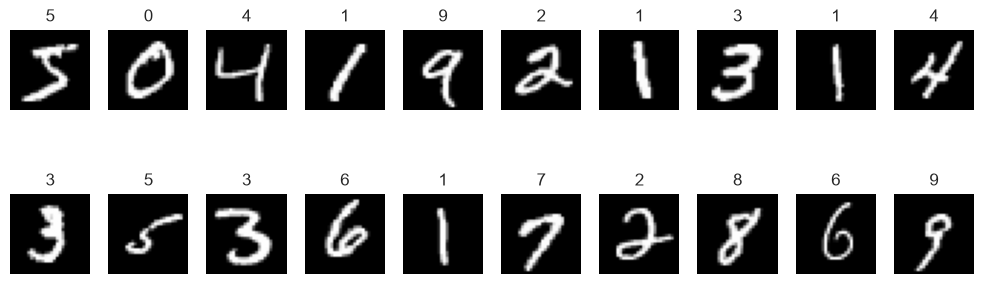

In [7]:
plt.figure(figsize=(10, 4))
for i in range(20):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_train[i], cmap='gray', vmin=0, vmax=255)
    plt.title(str(y_train[i]))
    plt.axis('off')
plt.tight_layout()
plt.show()

### Observations: displayed examples
The first displayed training image has supplied label **5** and visually shows a handwritten 5. The first 20 labels are `[5, 0, 4, 1, 9, 2, 1, 3, 1, 4, 3, 5, 3, 6, 1, 7, 2, 8, 6, 9]`. These fixed examples include all **10 digit labels**, with visible differences in stroke thickness, slant and shape.

The examples have light strokes on dark backgrounds. This small grid illustrates handwriting variation; it is not a random sample and cannot establish class prevalence. The full-training frequency table below supplies that evidence.

## 6. A small table for introductory exploration
We keep all image pixels in the original NumPy arrays to avoid making a large 784-column Pandas table. This small table contains only each image's digit label and its average pixel intensity. These summaries are for exploration, not replacement features for the later models.

**Classroom patterns:** the names `raw_data` and `data`, and `.copy()`, follow `Bank_Logistic_Regression.ipynb`, cells 2-4. `.head()` follows `Untitled.ipynb`, cell 3. Calculating `mean(axis=(1, 2))` is the necessary image-specific addition: it averages each image over its rows and columns.

In [8]:
raw_data = pd.DataFrame({
    'digit': y_train,
    'mean_pixel': x_train.mean(axis=(1, 2))
})
data = raw_data.copy()
data.head()

   digit  mean_pixel
0      5   35.108418
1      0   39.661990
2      4   24.799745
3      1   21.855867
4      9   29.609694


## 7. Introductory statistical analysis
`.describe()` reports the count, mean, standard deviation, minimum, quartiles and maximum of **per-image mean intensity**. Quartiles divide these image summaries into four ordered parts; the 50% value is their median. These are not quartiles of all individual pixels.

**Classroom pattern:** `linear regression.ipynb`, cell 4, uses `data.describe()`. We select the meaningful numerical column rather than treating digit labels as continuous measurements.

In [9]:
data[['mean_pixel']].describe()

         mean_pixel
count  60000.000000
mean      33.318421
std       11.041208
min        6.487245
25%       25.329082
50%       32.483418
75%       40.257653
max      101.381378


We also calculate the mean and population standard deviation of all training pixels. The mean describes average brightness; the standard deviation describes variation in pixel intensity. NumPy's default `std()` uses population standard deviation (`ddof=0`); Pandas `describe()` above reports sample standard deviation (`ddof=1`) of the per-image means, so these are different summaries.

**Statistical addition:** direct NumPy `mean()` and `std()` extend the classroom descriptive-statistics pattern to the image array. We reduce the existing uint8 array without retaining an extra floating-point image dataset.

In [10]:
pixel_mean = x_train.mean()
pixel_std = x_train.std()

print('Number of training pixels:', x_train.size)
print('Mean training pixel intensity: {0:.6f}'.format(pixel_mean))
print('Training pixel population standard deviation: {0:.6f}'.format(pixel_std))
print('Missing training pixel values:', np.isnan(x_train).sum())
print('Missing values in the summary table:')
print(data.isnull().sum())

Number of training pixels: 47040000
Mean training pixel intensity: 33.318421
Training pixel population standard deviation: 78.567490
Missing training pixel values: 0
Missing values in the summary table:
digit         0
mean_pixel    0
dtype: int64


### Observations: introductory statistics
Across **47,040,000 training pixels**, the observed range is **0-255**, the mean intensity is **33.318421**, and the population standard deviation is **78.567490**. The low mean relative to the 0-255 scale is consistent with dark backgrounds in the sample images. It does not imply that all images have the same brightness.

The explicit check reports **0 missing training pixel values**, and both summary columns have **0 missing values**. The uint8 data type cannot represent NaN, so this result is consistent with its numerical storage.

For the separate per-image mean-intensity summaries, `.describe()` reports a sample standard deviation of **11.041208**. This differs from the global pixel standard deviation because it describes variation between image averages, not variation between individual pixels. No arithmetic average of categorical digit labels is interpreted.

## 8. Examine the digit-class distribution
We count how often each digit occurs and divide each count by the total number of training images. For digit k, the empirical probability is its count divided by 60,000. Multiplying that proportion by 100 gives a percentage.

**Required additions:** `value_counts()` and `sort_index()` produce a simple ordered frequency table. These methods and empirical digit probabilities are not established in the main lesson demonstrations; they are needed to meet the brief's class-distribution requirement. We retain the familiar Pandas table style.

In [11]:
digit_counts = data['digit'].value_counts().sort_index()
class_distribution = pd.DataFrame({
    'count': digit_counts,
    'proportion': digit_counts / len(data),
    'percentage': digit_counts / len(data) * 100
})
class_distribution.index.name = 'digit'
class_distribution

       count  proportion  percentage
digit                               
0       5923    0.098717    9.871667
1       6742    0.112367   11.236667
2       5958    0.099300    9.930000
3       6131    0.102183   10.218333
4       5842    0.097367    9.736667
5       5421    0.090350    9.035000
6       5918    0.098633    9.863333
7       6265    0.104417   10.441667
8       5851    0.097517    9.751667
9       5949    0.099150    9.915000


In [12]:
print('Total counted training images:', class_distribution['count'].sum())
print('Sum of class proportions: {0:.6f}'.format(class_distribution['proportion'].sum()))
print('Least frequent training digit:', class_distribution['count'].idxmin())
print('Most frequent training digit:', class_distribution['count'].idxmax())

Total counted training images: 60000
Sum of class proportions: 1.000000
Least frequent training digit: 5
Most frequent training digit: 1


### Observations: digit distribution
All ten classes **0-9** occur. Their counts sum to **60,000**, and their empirical proportions sum to **1.000000**.

Digit **5** is least frequent: **5,421 images (9.035%)**. Digit **1** is most frequent: **6,742 images (11.237%)**. All class percentages fall between these limits, so the distribution is approximately balanced, though the counts are not identical. We retain all training examples; no balancing or resampling is performed.

A bar chart makes the ten class counts easy to compare. The vertical axis starts at zero so that small differences are not exaggerated.

**Classroom style:** axis labels, a title and `plt.show()` follow `linear regression.ipynb`, cell 6, and `Untitled10.ipynb`, cell 14. `plt.bar` is a required adaptation from scatter/line plots to categorical counts.

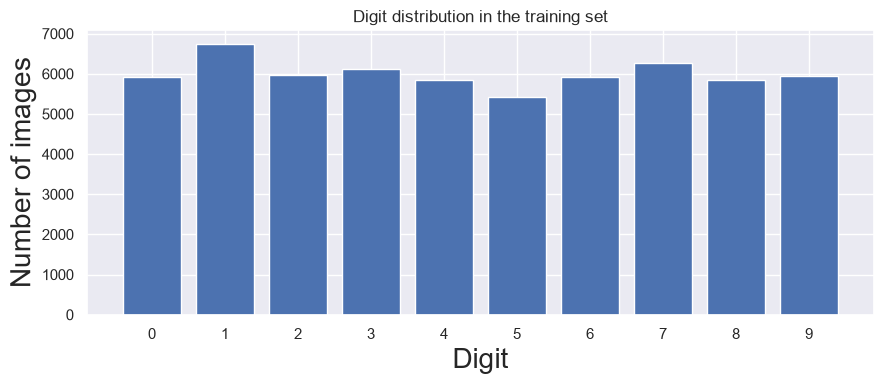

In [13]:
plt.figure(figsize=(9, 4))
plt.bar(class_distribution.index, class_distribution['count'])
plt.xticks(range(10))
plt.ylim(bottom=0)
plt.xlabel('Digit', fontsize=20)
plt.ylabel('Number of images', fontsize=20)
plt.title('Digit distribution in the training set')
plt.tight_layout()
plt.show()

## 9. Visualise the image-intensity summaries
The histogram groups the 60,000 **per-image mean intensities** into 30 bins. It shows how average image brightness varies across training examples, rather than showing a distribution of labels or all individual pixels.

**Required visualization addition:** `plt.hist` extends the lecturer's Matplotlib style to a numerical distribution. Plotting the small summary column avoids flattening all 47 million pixels into a separate plotting dataset.

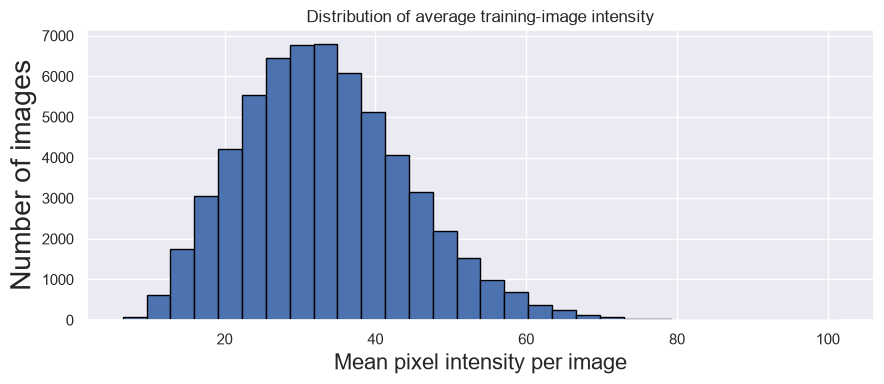

In [14]:
plt.figure(figsize=(9, 4))
plt.hist(data['mean_pixel'], bins=30, edgecolor='black')
plt.xlabel('Mean pixel intensity per image', fontsize=16)
plt.ylabel('Number of images', fontsize=20)
plt.title('Distribution of average training-image intensity')
plt.tight_layout()
plt.show()

### Observations: per-image intensity
Individual image mean intensities range from **6.487245** to **101.381378**. Their median is **32.483418**; the middle half lies between **25.329082** and **40.257653**.

The histogram shows one main peak around the low-to-mid 30s and a longer tail toward higher mean intensity. This is a visual description, not a formal distributional test. Mean brightness alone does not describe stroke position, identify a digit, or establish how difficult it will be to classify.

## Stage 1 conclusion
The executed investigation confirms **60,000 uint8 training images of shape 28 by 28**, with integer labels covering **all ten digits**. Training pixels span **0-255**. No missing training pixel or summary values were found. The classes are approximately balanced, and the sample displays and intensity summaries show variation across images.

### Stage 1 requirements from the project brief
| PDF page 2, Stage 1 requirement | Evidence in this notebook | Status |
|---|---|---|
| Load MNIST through the required Keras API | `tf.keras.datasets.mnist.load_data()` with the configured local cache | Pass |
| Inspect dimensions and structure | Array types, shapes, dimensions, dtypes, image size and memory summary | Pass |
| Inspect labels | First training labels, all distinct labels and class counts | Pass |
| Display sample images | First-image plot and labelled 20-image grid | Pass |
| Examine class distribution | Counts, empirical proportions, percentages and a bar chart | Pass |
| Include visualisations and basic statistical observations | Four verified figures, descriptive table, pixel statistics and actual-result observations | Pass |

All **14 code cells** executed in order using the specified `mnist_project` interpreter. Offline verification recorded **2 local dataset-file reads** and **0 network attempts**. The file hash matched the installed Keras loader's expected SHA-256: `731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1`. Outputs and four figure images are saved inside this notebook.

The previous download error (`WinError 10013`) was resolved by using the dataset cached from the student's normal Anaconda Prompt. No code-cell errors occurred in the successful offline execution. TensorFlow printed informational oneDNN startup messages; these did not prevent execution.

**Stage boundary:** the official test images and labels were returned by the required loader but were never inspected, analysed, evaluated or used for model tuning. No validation split, modelling normalization, model fitting or performance comparison has been performed. Passing Stage 1 does not establish model accuracy or complete the later project stages.

## Next stage: approval required
Stage 2 will create a reproducible training/validation split from the original 60,000 training examples, normalize pixels using the classroom float32/divide-by-255 method, and prepare the image shapes and integer targets for later modelling. Both model families will use the same split. The official test partition remains reserved for final evaluation.

No validation split, modelling normalization, Logistic Regression training or neural-network training has been performed in this notebook. Model fitting, tuning and final test evaluation require later approved stages.

# Stage 2: Data Preparation and Logistic Regression
The Stage 1 cells above are preserved as the completed exploration record. Their stage-boundary and approval notes describe the position at the end of Stage 1. The student has now approved this extension.

This stage covers preparation and Scikit-learn Logistic Regression (PDF page 2, methodology Stages 2 and 3), with **validation-only** evaluation using the measures on PDF page 3. The official MNIST test partition remains reserved for final evaluation. No neural network is built in this stage.

Classroom sources below use one-based cell positions, including markdown and empty cells. We retain short sequential cells and identify required additions.

## 10. Additional imports and output locations
We retain `np`, `pd`, `plt` and `seaborn` and the existing plotting style. Scikit-learn replaces Statsmodels because the brief requires it. Metric functions, warning capture, fit timing and model persistence are necessary additions not established in the lesson demonstrations.

**Classroom patterns:** `Bank_Logistic_Regression.ipynb`, cell 1; `logistics.ipynb`, cell 1; `linear regression.ipynb`, cell 1: direct imports and familiar aliases.

Artifacts go under this project's `models` and `results/stage2` directories. Re-running this stage replaces its generated artifacts with the newly measured run. Classroom sources are never written.

In [15]:
import time
import warnings
import json
import hashlib
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.exceptions import ConvergenceWarning

project_dir = os.path.dirname(os.environ['KERAS_HOME'])
models_dir = os.path.join(project_dir, 'models')
results_dir = os.path.join(project_dir, 'results', 'stage2')
os.makedirs(models_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

print('Scikit-learn version:', importlib.metadata.version('scikit-learn'))
print('Joblib version:', importlib.metadata.version('joblib'))
print('Models directory:', models_dir)
print('Results directory:', results_dir)

Scikit-learn version: 1.9.1
Joblib version: 1.6.0
Models directory: ./models
Results directory: ./results/stage2


## 11. Create the fixed training/validation split
Shuffle **indices**, then apply the same indices to images and labels to preserve their pairing. Starting from `np.random.seed(42)`, `np.arange(60000)` and one `np.random.shuffle` call, use the **first 54,000 shuffled indices for training** and the **last 6,000 for validation**. This is a random split, not a stratified split.

**Classroom patterns:** `Untitled20.ipynb`, cells 6-7: shuffled indices, paired indexing and slicing. `Untitled19.ipynb`, cell 1: 10% validation. We use 90%/10% of the original training partition only, with no new test split.

**Correctness adaptation:** one fixed NumPy partition avoids separately iterating the reshuffling `take`/`skip` datasets in `Untitled19.ipynb`, cell 4. A fixed seed and overlap/coverage assertions are additions for verified reproducibility.

In [16]:
split_seed = 42
np.random.seed(split_seed)

samples_count = x_train.shape[0]
shuffled_indices = np.arange(samples_count)
np.random.shuffle(shuffled_indices)

validation_samples_count = int(0.1 * samples_count)
train_samples_count = samples_count - validation_samples_count
train_indices = shuffled_indices[:train_samples_count]
validation_indices = shuffled_indices[train_samples_count:]

assert train_samples_count == 54000
assert validation_samples_count == 6000
assert np.intersect1d(train_indices, validation_indices).size == 0
assert np.array_equal(np.sort(np.concatenate((train_indices, validation_indices))), np.arange(samples_count))

print('Split seed:', split_seed)
print('Training images:', train_indices.size)
print('Validation images:', validation_indices.size)
print('Overlapping indices:', np.intersect1d(train_indices, validation_indices).size)
print('Total original training indices accounted for:', train_indices.size + validation_indices.size)

Split seed: 42
Training images: 54000
Validation images: 6000
Overlapping indices: 0
Total original training indices accounted for: 60000


## 12. Normalize pixels and retain integer labels
Select each partition, convert pixels to `float32`, and divide by 255 **in place**. Black becomes 0, white becomes 1. The fixed rule learns no validation or test statistics. Raw Stage 1 arrays remain unchanged.

**Classroom patterns:** `Untitled19.ipynb`, cell 3: float32 and division by 255. `Untitled20.ipynb`, cells 6-7 and 9: paired indexing and float32 inputs. MNIST labels already identify 0-9, so retain their integer dtype; the yes/no mapping in `logistics.ipynb`, cell 4, is unnecessary.

For 8 GB RAM, we do not retain a second full shuffled image array, normalize into duplicate floating-point arrays, or create a large Pandas feature table.

In [17]:
train_inputs = x_train[train_indices].astype(np.float32)
train_inputs /= 255.
train_targets = y_train[train_indices]

validation_inputs = x_train[validation_indices].astype(np.float32)
validation_inputs /= 255.
validation_targets = y_train[validation_indices]

assert train_inputs.dtype == np.float32
assert validation_inputs.dtype == np.float32
assert 0 <= train_inputs.min() <= train_inputs.max() <= 1
assert 0 <= validation_inputs.min() <= validation_inputs.max() <= 1
assert np.array_equal(train_targets, y_train[train_indices])
assert np.array_equal(validation_targets, y_train[validation_indices])
assert train_targets.dtype == y_train.dtype
assert validation_targets.dtype == y_train.dtype

print('Training inputs and targets:', train_inputs.shape, train_targets.shape)
print('Validation inputs and targets:', validation_inputs.shape, validation_targets.shape)
print('Prepared image dtype:', train_inputs.dtype)
print('Digit-label dtype:', train_targets.dtype)
print('Training pixel range:', train_inputs.min(), train_inputs.max())
print('Validation pixel range:', validation_inputs.min(), validation_inputs.max())
print('Total prepared image storage (MiB): {0:.2f}'.format((train_inputs.nbytes + validation_inputs.nbytes) / 1024**2))

Training inputs and targets: (54000, 28, 28) (54000,)
Validation inputs and targets: (6000, 28, 28) (6000,)
Prepared image dtype: float32
Digit-label dtype: uint8
Training pixel range: 0.0 1.0
Validation pixel range: 0.0 1.0
Total prepared image storage (MiB): 179.44


## 13. Prepare 784-feature rows
Each 28 by 28 image becomes one row of 784 numerical features, retaining row-major pixel order. Reshaping changes the shape, not values. `x` is the feature matrix and `y` is the digit-target vector. Image-shaped arrays remain available for the later approved neural network.

**Classroom patterns:** `Untitled13.ipynb`, cells 16-17 and 46: `.reshape()`. `Bank_Logistic_Regression.ipynb` and `logistics.ipynb`, cells 5-6: separate features/targets and familiar names.

The reshapes share storage with the float32 image arrays. Scikit-learn's `lbfgs` path can create an internal float64 fitting copy; this is separate from the retained prepared data.

In [18]:
input_size = 784
x = train_inputs.reshape(train_samples_count, input_size)
y = train_targets
validation_x = validation_inputs.reshape(validation_samples_count, input_size)

assert x.shape == (54000, 784)
assert validation_x.shape == (6000, 784)
assert np.shares_memory(x, train_inputs)
assert np.shares_memory(validation_x, validation_inputs)

print('x:', x.shape, x.dtype)
print('y:', y.shape, y.dtype)
print('validation_x:', validation_x.shape, validation_x.dtype)
print('validation_targets:', validation_targets.shape, validation_targets.dtype)
print('Training reshape shares image storage:', np.shares_memory(x, train_inputs))
print('Validation reshape shares image storage:', np.shares_memory(validation_x, validation_inputs))

x: (54000, 784) float32
y: (54000,) uint8
validation_x: (6000, 784) float32
validation_targets: (6000,) uint8
Training reshape shares image storage: True
Validation reshape shares image storage: True


## 14. Check class representation and save the exact split
This small table checks representation of all digits. We retain all examples rather than equalizing counts. Save the index arrays so the later network uses exactly the same membership and order.

**Classroom pattern:** `Untitled20.ipynb`, cell 8: `np.savez`. Saving indices instead of entire normalized image partitions avoids redundant large files. The seed and complete splitting rule are also saved in run metadata.

In [19]:
split_distribution = pd.DataFrame({
    'Training': pd.Series(train_targets).value_counts().sort_index(),
    'Validation': pd.Series(validation_targets).value_counts().sort_index()
})
split_distribution.index.name = 'digit'

assert np.array_equal(split_distribution.index.to_numpy(), np.arange(10))
assert (split_distribution > 0).all().all()
assert split_distribution['Training'].sum() == train_samples_count
assert split_distribution['Validation'].sum() == validation_samples_count

split_path = os.path.join(results_dir, 'split_indices.npz')
np.savez(split_path, train=train_indices, validation=validation_indices)
split_distribution.to_csv(os.path.join(results_dir, 'split_distribution.csv'))
split_distribution

       Training  Validation
digit                      
0          5334         589
1          6068         674
2          5369         589
3          5553         578
4          5258         584
5          4891         530
6          5309         609
7          5642         623
8          5226         625
9          5350         599


### Executed preparation observations
The fixed seed is **42**. One NumPy shuffle of indices 0-59,999 produced **54,000 training** and **6,000 validation** examples, with **zero overlapping indices** and complete coverage of all 60,000 original training examples. All ten digit classes are represented in both partitions.

The image inputs are float32 and both observed ranges are **0.0-1.0**. Targets remain uint8 digit labels. Logistic Regression receives `x` of shape **(54000, 784)** and `y` of shape **(54000,)**; validation features and targets have shapes **(6000, 784)** and **(6000,)**. Both reshapes share their image-array storage. The retained normalized images together occupy **179.44 MiB**, excluding raw data, framework memory and temporary solver arrays.

The exact ordered index arrays are saved in `results/stage2/split_indices.npz`; seed, splitting rule and index hashes are recorded in the run JSON. Reuse these indices for the neural network rather than making another random split.

## 15. From classroom Statsmodels to Scikit-learn
`Bank_Logistic_Regression.ipynb` and `logistics.ipynb`, cells 5-6, select features/targets, add a constant and fit `reg_log = sm.Logit(y, x)`. `Bank_Data_Logistic_Regression (1).ipynb`, cells 6-8, inspects fitted coefficients and probabilities.

Here the brief requires **Scikit-learn**. Retain the simple sequence and names with `reg_log = LogisticRegression(...)`, `.fit(x, y)` and `.predict(validation_x)`. Scikit-learn handles the intercept, so do **not** add a constant. It fits ten-class multinomial Logistic Regression rather than the classroom binary model.

For class k, the score is `z_k = w_k dot x + b_k`. Softmax turns scores into probabilities, and prediction selects the largest. Training minimizes multinomial cross-entropy with regularization. No hidden layers are involved. This multiclass explanation extends the binary lesson.

Use approved settings **C=1.0, solver='lbfgs', max_iter=1000**, default tolerance `1e-4`. `C` is inverse regularization strength; `max_iter` caps solver iterations, not neural-network epochs. Scikit-learn 1.9.1 supports these directly. Omit deprecated `penalty`, `multi_class` and `n_jobs` arguments, retaining default L2 regularization.

**Installed API evidence:** `<environment>/Lib/site-packages/sklearn/linear_model/_logistic.py`, constructor line 1277, `fit` line 1333. These are library-source references, not claims of classroom API coverage.

## 16. Fit only the training partition
Time only `.fit(x, y)` using `time.perf_counter()`, excluding preparation, loading, plotting, prediction and saving. Validation does not enter this fit.

**Classroom fitting pattern:** `Bank_Data_Logistic_Regression (1).ipynb`, cell 6. Timing and warning capture are necessary additions. Record every fit warning and stop if a `ConvergenceWarning` occurs, so an unfinished fit is not silently evaluated or saved. Document any needed correction before final test evaluation.

In [20]:
reg_log = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000)

with warnings.catch_warnings(record=True) as training_warnings:
    warnings.simplefilter('always')
    start_time = time.perf_counter()
    reg_log.fit(x, y)
    logistic_training_time = time.perf_counter() - start_time

convergence_warnings = [message for message in training_warnings if issubclass(message.category, ConvergenceWarning)]
for message in training_warnings:
    print(message.category.__name__ + ': ' + str(message.message))

print('Training time (seconds): {0:.6f}'.format(logistic_training_time))
print('Solver iterations:', reg_log.n_iter_)
print('Fit warnings:', len(training_warnings))
print('Convergence warnings:', len(convergence_warnings))
assert len(convergence_warnings) == 0, 'Resolve the convergence warning before evaluating or saving this model.'
assert reg_log.n_features_in_ == input_size
assert np.array_equal(reg_log.classes_, np.arange(10))

Training time (seconds): 52.845251
Solver iterations: [235]
Fit warnings: 0
Convergence warnings: 0


### Executed fit observations
The approved classifier converged after **235 iterations**, below the maximum of 1,000. There were **0 fit warnings** and **0 convergence warnings**. The settings remain **C=1.0, solver='lbfgs', max_iter=1000**; no compatibility correction, parameter search or retry was needed.

The measured fit-call time was **52.845251 seconds**. The verification process used two BLAS/OpenMP threads, recorded in the run metadata. This is one CPU-run timing, excluding data preparation, prediction and saving. Other machines, workloads or thread settings can produce different times.

## 17. Validation predictions and multiclass metrics
`.predict()` gives one digit per validation image. **Accuracy** is the proportion correct. For each digit versus the other nine: **precision** = TP/(TP+FP), **recall** = TP/(TP+FN), **F1** = 2TP/(2TP+FP+FN). TP, FP and FN mean true positives, false positives and false negatives.

Use **macro precision, macro recall and macro F1**: calculate separately for each digit, then take an unweighted mean over all ten classes. Macro F1 is the average per-class F1, not F1 computed from macro precision/recall. `zero_division=0` supplies zero for undefined ratios. The per-digit report includes support (actual count) and weighted averages.

**Classroom patterns:** `Bank_Data_Logistic_Regression (1).ipynb`, cells 8 and 10-12, demonstrates predictions, actual/predicted tables and accuracy; cells 18-21 evaluate held-out examples. Scikit-learn multiclass metric functions, averaging and the report are required additions. Here all evaluation is on validation, never the official test partition.

In [21]:
validation_predictions = reg_log.predict(validation_x)
validation_accuracy = accuracy_score(validation_targets, validation_predictions)
validation_precision = precision_score(validation_targets, validation_predictions, labels=range(10), average='macro', zero_division=0)
validation_recall = recall_score(validation_targets, validation_predictions, labels=range(10), average='macro', zero_division=0)
validation_f1 = f1_score(validation_targets, validation_predictions, labels=range(10), average='macro', zero_division=0)

validation_results = pd.DataFrame({
    'Model': ['Logistic Regression'],
    'Evaluation partition': ['Validation only'],
    'Accuracy': [validation_accuracy],
    'Macro precision': [validation_precision],
    'Macro recall': [validation_recall],
    'Macro F1': [validation_f1],
    'Training time (seconds)': [logistic_training_time]
})
validation_results

                 Model  ...  Training time (seconds)
0  Logistic Regression  ...                52.845251

[1 rows x 7 columns]


In [22]:
print(classification_report(validation_targets, validation_predictions, labels=range(10), digits=4, zero_division=0))
print('Validation misclassification rate: {0:.4f}%'.format((1 - validation_accuracy) * 100))

              precision    recall  f1-score   support

           0     0.9564    0.9694    0.9629       589
           1     0.9495    0.9763    0.9627       674
           2     0.9270    0.8846    0.9053       589
           3     0.9182    0.8737    0.8954       578
           4     0.9223    0.9349    0.9286       584
           5     0.8806    0.8906    0.8856       530
           6     0.9583    0.9442    0.9512       609
           7     0.9348    0.9438    0.9393       623
           8     0.8815    0.8928    0.8871       625
           9     0.9013    0.9149    0.9080       599

    accuracy                         0.9237      6000
   macro avg     0.9230    0.9225    0.9226      6000
weighted avg     0.9237    0.9237    0.9235      6000

Validation misclassification rate: 7.6333%


## 18. Validation confusion matrix
Rows are **actual digits**, columns are **predicted digits**. The diagonal counts correct predictions. Entries must sum to 6,000; the diagonal sum divided by 6,000 must equal validation accuracy.

**Classroom patterns:** `Bank_Data_Logistic_Regression (1).ipynb`, cells 10-12 and 18-20: labelled confusion tables and diagonal-based accuracy. Extend to ten classes with Scikit-learn's `confusion_matrix`; the classroom binary 0.5-cutoff histogram is unsuitable.

The Pandas table follows the bank example. The annotated Seaborn heatmap is a visualization addition; labelling and `plt.show()` follow `linear regression.ipynb`, cell 6.

In [23]:
cm = confusion_matrix(validation_targets, validation_predictions, labels=range(10))
cm_df = pd.DataFrame(cm, index=range(10), columns=range(10))
cm_df.index.name = 'Actual digit'
cm_df.columns.name = 'Predicted digit'

assert cm.shape == (10, 10)
assert cm.sum() == validation_samples_count
accuracy_from_cm = np.trace(cm) / cm.sum()
assert np.isclose(accuracy_from_cm, validation_accuracy)
print('Accuracy from confusion matrix: {0:.6f}'.format(accuracy_from_cm))
cm_df

Accuracy from confusion matrix: 0.923667


Predicted digit    0    1    2    3    4    5    6    7    8    9
Actual digit                                                     
0                571    0    4    2    0    5    4    1    2    0
1                  0  658    1    1    1    2    0    2    9    0
2                  5    7  521    6    9    1    5    8   21    6
3                  2    4   15  505    1   24    2    7   12    6
4                  3    1    2    1  546    3    3    3    7   15
5                  6    2    1   11   12  472    9    1   12    4
6                  6    3    4    0    4    9  575    1    7    0
7                  0    3    4    1    4    0    1  588    1   21
8                  4   13    8   16    1   15    1    1  558    8
9                  0    2    2    7   14    5    0   17    4  548


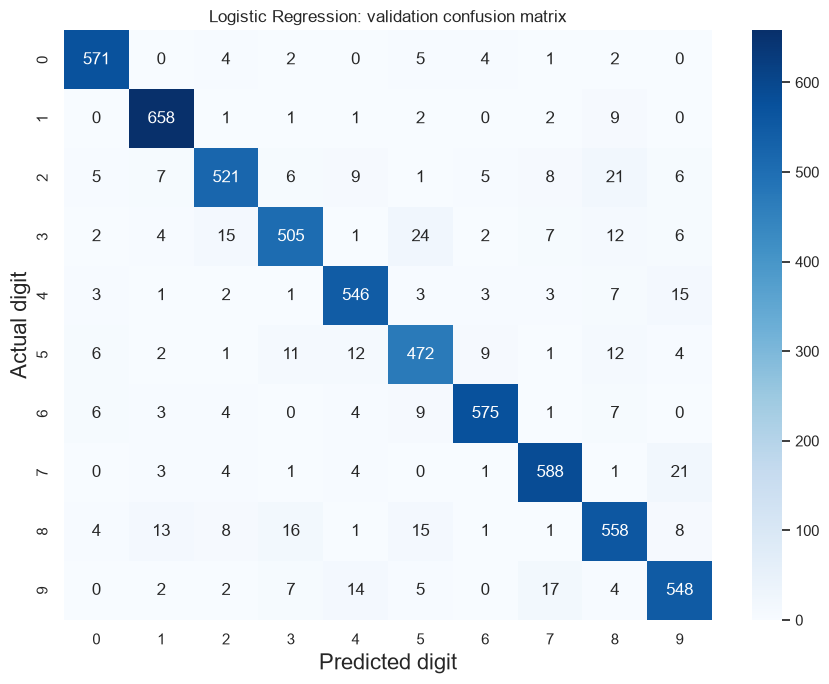

In [24]:
plt.figure(figsize=(9, 7))
seaborn.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted digit', fontsize=16)
plt.ylabel('Actual digit', fontsize=16)
plt.title('Logistic Regression: validation confusion matrix')
plt.tight_layout()
plt.savefig(os.path.join(results_dir, 'logistic_validation_confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()

### Executed validation results
| Measure | Actual validation result |
|---|---:|
| Accuracy | 0.9236666667 (92.3667%) |
| Macro precision | 0.9230049135 |
| Macro recall | 0.9225100001 |
| Macro F1 | 0.9226062575 |
| Correct predictions | 5,542 / 6,000 |
| Incorrect predictions | 458 / 6,000 |
| Training time | 52.845251 seconds |

The 10 by 10 confusion matrix sums to **6,000** and its diagonal sums to **5,542**. The diagonal-based accuracy equals the library accuracy. Independent reconstruction from the actual/predicted labels also reproduced the entire matrix and all four headline metrics.

The largest off-diagonal entry is actual digit **3** predicted as **5** (**24** images). Actual **2** predicted as **8** and actual **7** predicted as **9** each occur **21** times. Digit **3** has the lowest recall (**0.873702**); digit **1** has the highest (**0.976261**). These observations describe this one validation partition; they do not establish the causes of the errors.

The visible diagonal shows that most predictions are correct, but 458 errors remain. These are validation measurements for a fixed configuration and split, not final test performance or measured accuracy on new photographs.

## 19. Save the classifier and validation artifacts
`joblib.dump` is a required addition for saving Scikit-learn estimators. `Untitled20.ipynb`, cell 8, demonstrates saving arrays with `np.savez`; follow that straightforward save/load sequence for the split and validation predictions.

The fitted model expects **a two-dimensional array with 784 features per image**: original MNIST-style 28 by 28 grayscale pixels converted to float32, divided by 255, then reshaped in C/row-major order. Labels remain 0-9. The model stores weights/intercepts, not normalization or resizing. Save that contract beside it.

Record versions, settings, split seed/method, hashes, warnings, actual metrics, fit time and computational thread settings. Timing is one fit on this computer and varies across runs. No test-set result is saved.

In [25]:
model_path = os.path.join(models_dir, 'logistic_regression.joblib')
joblib.dump(reg_log, model_path)

validation_results.to_csv(os.path.join(results_dir, 'logistic_validation_metrics.csv'), index=False)
cm_df.to_csv(os.path.join(results_dir, 'logistic_validation_confusion_matrix.csv'))
np.savez(os.path.join(results_dir, 'logistic_validation_predictions.npz'),
         validation_indices=validation_indices, actual=validation_targets, predicted=validation_predictions)

with open(dataset_path, 'rb') as file:
    dataset_sha256 = hashlib.sha256(file.read()).hexdigest()
with open(model_path, 'rb') as file:
    model_sha256 = hashlib.sha256(file.read()).hexdigest()

run_record = {
    'stage': 'Stage 2: data preparation and Logistic Regression; validation only',
    'completed_utc': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
    'python_executable': sys.executable,
    'python_version': sys.version.split()[0],
    'versions': {name: importlib.metadata.version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'tensorflow', 'keras', 'joblib', 'matplotlib', 'seaborn']},
    'dataset_sha256': dataset_sha256,
    'split_seed': split_seed,
    'split_method': 'np.random.seed(42); np.arange(60000); np.random.shuffle once; first 54000 train, remaining 6000 validation',
    'training_images': train_samples_count,
    'validation_images': validation_samples_count,
    'train_indices_sha256': hashlib.sha256(train_indices.tobytes()).hexdigest(),
    'validation_indices_sha256': hashlib.sha256(validation_indices.tobytes()).hexdigest(),
    'index_dtype': str(train_indices.dtype),
    'training_class_counts': [int(value) for value in split_distribution['Training']],
    'validation_class_counts': [int(value) for value in split_distribution['Validation']],
    'preprocessing': 'Original uint8 MNIST pixels -> float32 -> divide by 255 in place -> reshape each image to 784 features in C/row-major order',
    'settings': {'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1000, 'tol': reg_log.tol, 'fit_intercept': reg_log.fit_intercept},
    'solver_iterations': [int(value) for value in reg_log.n_iter_],
    'fit_warnings': [{'category': message.category.__name__, 'message': str(message.message)} for message in training_warnings],
    'convergence_warnings': len(convergence_warnings),
    'metrics_average': 'macro over all ten digits; zero_division=0',
    'validation_metrics': {'accuracy': validation_accuracy, 'macro_precision': validation_precision, 'macro_recall': validation_recall, 'macro_f1': validation_f1},
    'training_time_seconds': logistic_training_time,
    'timing_scope': 'One fit call; excludes loading, preparation, prediction, plotting and saving',
    'thread_environment': {name: os.environ.get(name) for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']},
    'model_file': 'models/logistic_regression.joblib',
    'model_sha256': model_sha256,
    'test_partition': 'Reserved; never inspected, transformed, predicted or evaluated in Stage 2'
}
with open(os.path.join(results_dir, 'logistic_regression_run.json'), 'w', encoding='utf-8') as file:
    json.dump(run_record, file, indent=2)

preprocessing_notes = '''# Logistic Regression preprocessing and reuse

Model: logistic_regression.joblib (Scikit-learn LogisticRegression).
Use the recorded mnist_project environment and versions in
results/stage2/logistic_regression_run.json.

1. Start with MNIST-style 28 by 28 grayscale images, dark background and light strokes.
2. Raw pixels use the original 0-255 range. Arbitrary photographs need additional work.
3. Convert to NumPy float32 and divide by 255 exactly once.
4. Reshape to (number_of_images, 784), using C/row-major pixel order.
5. Call the loaded classifier's predict method; outputs are digits 0-9.

Example using already prepared validation_x from the notebook:
    loaded_reg_log = joblib.load(model_path)
    predictions = loaded_reg_log.predict(validation_x)

The model does not contain normalization or resizing. Do not divide normalized
pixels by 255 again. Integer labels are not scaled. Exact train/validation indices
are in results/stage2/split_indices.npz. The official test set remains reserved.
'''
with open(os.path.join(models_dir, 'logistic_regression_preprocessing.md'), 'w', encoding='utf-8') as file:
    file.write(preprocessing_notes)
print('Saved model:', model_path)
print('Saved split:', split_path)
print('Saved validation metrics, confusion matrix, predictions and run metadata.')

Saved model: ./models/logistic_regression.joblib
Saved split: ./results/stage2/split_indices.npz
Saved validation metrics, confusion matrix, predictions and run metadata.


## 20. Reload and verify validation predictions
Reload the model and require its predictions to match the in-memory classifier on **all 6,000 validation images**. This verifies serialization, not that every prediction is correct against the label. The table distinguishes those checks.

**Classroom relationship:** `Untitled20.ipynb`, cell 9, demonstrates direct array reloading. `joblib.load`, prediction-equivalence assertions and the verification table are additions required for the trained-model artifact.

In [26]:
loaded_reg_log = joblib.load(model_path)
loaded_validation_predictions = loaded_reg_log.predict(validation_x)
assert np.array_equal(loaded_validation_predictions, validation_predictions)
assert np.array_equal(loaded_reg_log.classes_, reg_log.classes_)
assert loaded_reg_log.n_features_in_ == input_size
assert np.isclose(accuracy_score(validation_targets, loaded_validation_predictions), validation_accuracy)

print('Reloaded-model predictions match all 6,000 original validation predictions.')
print('Reloaded-model validation accuracy: {0:.6f}'.format(accuracy_score(validation_targets, loaded_validation_predictions)))
validation_examples = pd.DataFrame({
    'Original training index': validation_indices[:10],
    'Actual digit': validation_targets[:10],
    'Reloaded model prediction': loaded_validation_predictions[:10],
    'Correct': loaded_validation_predictions[:10] == validation_targets[:10]
})
run_record['reload_prediction_match'] = True
run_record['reloaded_validation_images'] = int(loaded_validation_predictions.size)
with open(os.path.join(results_dir, 'logistic_regression_run.json'), 'w', encoding='utf-8') as file:
    json.dump(run_record, file, indent=2)
validation_examples

Reloaded-model predictions match all 6,000 original validation predictions.
Reloaded-model validation accuracy: 0.923667


   Original training index  Actual digit  Reloaded model prediction  Correct
0                    14026             3                          3     True
1                    25613             4                          4     True
2                    14232             6                          6     True
3                    24229             2                          2     True
4                    52691             0                          0     True
5                     2217             4                          4     True
6                     5232             2                          2     True
7                    30453             9                          7    False
8                    54784             1                          1     True
9                    30257             9                          9     True


## Stage 2 conclusion and verification
The trained Logistic Regression model reached **92.3667% validation accuracy** with **macro F1 0.922606**, using only the 54,000-image fitting partition. No solver-setting change was necessary.

| Required verification | Actual evidence | Status |
|---|---|---|
| All code cells execute | All **26** code cells ran in order with the exact `mnist_project` interpreter | Pass |
| Correct dataset shapes | 54,000/6,000 image partitions and 784-feature matrices | Pass |
| Disjoint and exhaustive split | No overlap, complete coverage and independent seed-42 split reproduction | Pass |
| Correct normalization | Float32, range 0-1; every prepared pixel checked against raw/255 in small batches | Pass |
| Successful Logistic Regression fit | 235 iterations; no convergence or other fit warnings | Pass |
| Correct multiclass metrics | Macro values independently recomputed from per-class counts | Pass |
| Correct confusion matrix | Reconstructed from predictions; 6,000 entries, diagonal 5,542 | Pass |
| Saved and reloadable model | Reloaded artifact matches all 6,000 in-memory validation predictions | Pass |
| Official test partition remains reserved | No test-array reads after loading; no test preprocessing, prediction or evaluation | Pass |

The first ten reload examples include one wrong digit prediction. This is expected given the measured validation error rate: serialization equivalence does not mean perfect classification. The model and its preprocessing contract are saved in `models/`; the exact split, counts, validation metrics, predictions, confusion matrix and run metadata are in `results/stage2/`.

The successful execution used the local MNIST cache with **zero network attempts**. All original Stage 1 cells, explanations, outputs and graphs are unchanged. No neural-network model has been created or trained. Stage 2 is complete; later neural-network experiments and final test evaluation remain subject to approval.

## Stop before Stage 3
Stage 2 ends with a trained, saved, verified Logistic Regression classifier and **validation** results. These are not final test scores. The original test partition remains reserved.

After approval, build a simple Keras network using the **same saved indices** and conduct the approved validation experiment. No neural network has been built, compiled, trained or evaluated here.

# Stage 3: Neural Networks and Deep Learning
The approved Stage 1 and Stage 2 cells above are retained as their original execution records. Their earlier stopping notes describe the boundaries at that time; Stage 3 is now approved.

Follow the classroom Keras build, compile, fit and evaluate sequence. Compare two dense networks using only the original 54,000 training images and 6,000 validation images, then select by final validation accuracy. This addresses the PDF's simple-network experiment requirement (page 2) and makes a preliminary validation comparison (page 3). It does not perform final test evaluation.

No CNN, transfer learning, custom training loop, early stopping, new partition or further parameter search is introduced. The official test images and labels are never referenced by this stage.

## 21. Reuse and verify the Stage 2 data
Reuse `train_inputs`, `train_targets`, `validation_inputs` and `validation_targets` from Stage 2. Load the saved index arrays and verify exact equality with the indices used for Logistic Regression, including order and target labels. No shuffling or repartitioning of the original dataset occurs here.

The images stay float32 with shape (54000, 28, 28) and (6000, 28, 28), normalized to [0,1]. Keep integer digit targets. Keras may shuffle the order of training batches within an epoch; this does not change training/validation membership.

**Classroom sources:** `Untitled20.ipynb`, cells 8-9 (saving/reloading NumPy arrays), cells 6-7 (paired image/target indexing); `Untitled19.ipynb`, cell 3 (float32 pixels divided by 255). Assertions and index hashes are additions for verified reuse. No extra full image copies are made.

In [27]:
stage3_results_dir = os.path.join(project_dir, 'results', 'stage3')
os.makedirs(stage3_results_dir, exist_ok=True)

with open(os.path.join(project_dir, 'results', 'stage2', 'logistic_regression_run.json'), encoding='utf-8') as file:
    lr_run = json.load(file)
with np.load(os.path.join(project_dir, 'results', 'stage2', 'split_indices.npz')) as saved_split:
    saved_train_indices = saved_split['train']
    saved_validation_indices = saved_split['validation']

assert np.array_equal(train_indices, saved_train_indices)
assert np.array_equal(validation_indices, saved_validation_indices)
assert hashlib.sha256(train_indices.tobytes()).hexdigest() == lr_run['train_indices_sha256']
assert hashlib.sha256(validation_indices.tobytes()).hexdigest() == lr_run['validation_indices_sha256']
assert np.intersect1d(train_indices, validation_indices).size == 0
assert np.array_equal(np.sort(np.concatenate((train_indices, validation_indices))), np.arange(60000))
assert train_inputs.shape == (54000, 28, 28)
assert validation_inputs.shape == (6000, 28, 28)
assert train_inputs.dtype == validation_inputs.dtype == np.float32
assert 0 <= train_inputs.min() <= train_inputs.max() <= 1
assert 0 <= validation_inputs.min() <= validation_inputs.max() <= 1
assert np.array_equal(train_targets, y_train[saved_train_indices])
assert np.array_equal(validation_targets, y_train[saved_validation_indices])
assert np.issubdtype(train_targets.dtype, np.integer)
assert np.issubdtype(validation_targets.dtype, np.integer)
print('Exact Stage 2 split and labels verified: 54,000 training, 6,000 validation.')
print('Image shapes:', train_inputs.shape, validation_inputs.shape)
print('Image dtype:', train_inputs.dtype, 'Target dtype:', train_targets.dtype)
print('No new dataset partition or normalized image copy created in Stage 3.')

Exact Stage 2 split and labels verified: 54,000 training, 6,000 validation.
Image shapes: (54000, 28, 28) (6000, 28, 28)
Image dtype: float32 Target dtype: uint8
No new dataset partition or normalized image copy created in Stage 3.


## 22. Explain and build the 50-unit classroom model
- **Input (28,28):** one normalized grayscale image per example.
- **Flatten:** rearranges 28 by 28 pixels into 784 values; it has no learned parameters.
- **Dense(50, ReLU), twice:** each neuron computes a weighted sum plus a learned bias. ReLU keeps positive values and replaces negative values with zero, introducing nonlinearity.
- **Dense(10, Softmax):** one output per digit; converts scores into ten probabilities summing to one. The largest gives the predicted label. These scores are model probabilities, not guarantees of correctness.

**Classroom sources:** `Untitled19.ipynb`, cell 7, supplies Flatten and two 50-unit ReLU layers. Correct its output-layer mistake by using **`output_size=10`**, not `hidden_layer_size`, for softmax. `Untitled20.ipynb`, cell 10, demonstrates an explicit `Input` and `Dense(output_size, activation='softmax')`. With Keras NumPy images the input shape is (28,28), without the TFDS singleton channel.

**Weights and optimization:** `Untitled18.ipynb`, cells 4-7, builds a Dense model and inspects its learned weights/bias. `Untitled14.ipynb`, cells 5-7, illustrates initialization, loss and weight updates. Here use the taught Adam optimizer and sparse categorical cross-entropy (`Untitled19.ipynb`, cell 8). The loss accepts integer labels and penalizes low probability assigned to the true digit. Backpropagation computes gradients; Adam updates weights using those gradients.

Use initialization seed **42** before each model. `tf.keras.utils.set_random_seed` is a reproducibility addition; different layer widths still produce different weight arrays. This is one run per setting, not a repeated-seed experiment.

In [28]:
NN_SEED = 42
BATCH_SIZE = 100
NUM_EPOCHS = 5
input_size = 784
output_size = 10
hidden_layer_size = 50

tf.keras.utils.set_random_seed(NN_SEED)
model_50 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(hidden_layer_size, activation='relu'),
    tf.keras.layers.Dense(hidden_layer_size, activation='relu'),
    tf.keras.layers.Dense(output_size, activation='softmax')
])
model_50.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
assert model_50.output_shape == (None, 10)
assert model_50.layers[-1].units == 10
assert model_50.count_params() == 42310
model_50.summary()

Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │        39,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 42,310 (165.27 KB)
 Trainable params: 42,310 (165.27 KB)
 Non-trainable params: 0 (0.00 B)


## 23. Train the first configuration
Train for five complete passes through the 54,000 fitting images, in batches of 100. Validation checks progress after each epoch but does not update weights. Measure `.fit()` only, including its epoch-validation work; saving and subsequent prediction are excluded.

**Classroom sources:** `Untitled19.ipynb`, cells 5-6 and 9: batch size 100, five epochs and validation. `Untitled20.ipynb`, cell 12: NumPy-array `.fit(..., validation_data=...)`. Correct its hardcoded batch-size mismatch by passing the declared `BATCH_SIZE`. `verbose=2` keeps output to one summary per epoch. Recording the returned History, fit time and a native model artifact are required additions.

In [29]:
start_time = time.perf_counter()
history_50 = model_50.fit(
    train_inputs, train_targets,
    batch_size=BATCH_SIZE,
    epochs=NUM_EPOCHS,
    validation_data=(validation_inputs, validation_targets),
    verbose=2
)
neural_50_training_time = time.perf_counter() - start_time
model_50_path = os.path.join(models_dir, 'neural_network_50.keras')
model_50.save(model_50_path)
print('50-unit fit time (seconds): {0:.6f}'.format(neural_50_training_time))

Epoch 1/5
540/540 - 8s - 14ms/step - accuracy: 0.8875 - loss: 0.4046 - val_accuracy: 0.9335 - val_loss: 0.2171
Epoch 2/5
540/540 - 4s - 8ms/step - accuracy: 0.9486 - loss: 0.1774 - val_accuracy: 0.9488 - val_loss: 0.1655
Epoch 3/5
540/540 - 3s - 5ms/step - accuracy: 0.9606 - loss: 0.1340 - val_accuracy: 0.9565 - val_loss: 0.1428
Epoch 4/5
540/540 - 3s - 6ms/step - accuracy: 0.9686 - loss: 0.1085 - val_accuracy: 0.9625 - val_loss: 0.1272
Epoch 5/5
540/540 - 5s - 10ms/step - accuracy: 0.9731 - loss: 0.0912 - val_accuracy: 0.9640 - val_loss: 0.1187
50-unit fit time (seconds): 23.747066


## 24. Change only hidden-layer width to 100
Reset the same initialization seed and build a second model with **100 units in each hidden layer**. Keep the split, image values, output size, activations, optimizer, loss, epochs and batch size unchanged. Train after the first fit finishes. Both small parameter sets can remain in memory without duplicating the image data.

This controlled two-setting experiment is required by the brief. The construction and compile/fit sequence directly repeat `Untitled19.ipynb`, cells 7-9. No early stopping or extra settings are added; selection will use the final fifth-epoch validation accuracy.

In [30]:
tf.keras.utils.set_random_seed(NN_SEED)
hidden_layer_size_100 = 100
model_100 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(hidden_layer_size_100, activation='relu'),
    tf.keras.layers.Dense(hidden_layer_size_100, activation='relu'),
    tf.keras.layers.Dense(output_size, activation='softmax')
])
model_100.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
assert model_100.output_shape == (None, 10)
assert model_100.layers[-1].units == 10
assert model_100.count_params() == 89610
model_100.summary()

Model: "sequential_1"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 89,610 (350.04 KB)
 Trainable params: 89,610 (350.04 KB)
 Non-trainable params: 0 (0.00 B)


In [31]:
start_time = time.perf_counter()
history_100 = model_100.fit(
    train_inputs, train_targets,
    batch_size=BATCH_SIZE,
    epochs=NUM_EPOCHS,
    validation_data=(validation_inputs, validation_targets),
    verbose=2
)
neural_100_training_time = time.perf_counter() - start_time
model_100_path = os.path.join(models_dir, 'neural_network_100.keras')
model_100.save(model_100_path)
print('100-unit fit time (seconds): {0:.6f}'.format(neural_100_training_time))

Epoch 1/5
540/540 - 8s - 14ms/step - accuracy: 0.9058 - loss: 0.3334 - val_accuracy: 0.9412 - val_loss: 0.1944
Epoch 2/5
540/540 - 4s - 8ms/step - accuracy: 0.9586 - loss: 0.1402 - val_accuracy: 0.9542 - val_loss: 0.1423
Epoch 3/5
540/540 - 4s - 7ms/step - accuracy: 0.9708 - loss: 0.0981 - val_accuracy: 0.9660 - val_loss: 0.1104
Epoch 4/5
540/540 - 4s - 7ms/step - accuracy: 0.9773 - loss: 0.0754 - val_accuracy: 0.9698 - val_loss: 0.0976
Epoch 5/5
540/540 - 3s - 6ms/step - accuracy: 0.9821 - loss: 0.0596 - val_accuracy: 0.9728 - val_loss: 0.0932
100-unit fit time (seconds): 23.330180


## 25. Record both trials
Report the final epoch's training accuracy/loss and validation accuracy/loss, measured fit time and parameter count. Training metrics summarize batches while weights are updated during that epoch; validation metrics use its final weights. The History tables retain all five epochs.

Pandas tables follow the classroom data-inspection style. Recording Keras History and parameter counts is an experiment-documentation addition; `model.summary()` makes layer sizes and learned parameters visible.

In [32]:
nn_trial_results = pd.DataFrame({
    'Hidden units per layer': [50, 100],
    'Parameters': [model_50.count_params(), model_100.count_params()],
    'Training accuracy': [history_50.history['accuracy'][-1], history_100.history['accuracy'][-1]],
    'Validation accuracy': [history_50.history['val_accuracy'][-1], history_100.history['val_accuracy'][-1]],
    'Training loss': [history_50.history['loss'][-1], history_100.history['loss'][-1]],
    'Validation loss': [history_50.history['val_loss'][-1], history_100.history['val_loss'][-1]],
    'Training time (seconds)': [neural_50_training_time, neural_100_training_time]
})
nn_trial_results.to_csv(os.path.join(stage3_results_dir, 'neural_network_trials.csv'), index=False)
pd.DataFrame(history_50.history).to_csv(os.path.join(stage3_results_dir, 'history_50.csv'), index_label='epoch_zero_based')
pd.DataFrame(history_100.history).to_csv(os.path.join(stage3_results_dir, 'history_100.csv'), index_label='epoch_zero_based')
nn_trial_results

   Hidden units per layer  ...  Training time (seconds)
0                      50  ...                23.747066
1                     100  ...                23.330180

[2 rows x 7 columns]


### Executed trial results
Both configurations trained successfully for five epochs, sequentially, with initialization seed **42**, batch size **100**, Adam (learning rate approximately **0.001**) and sparse categorical cross-entropy. Both have exactly **ten softmax outputs**.

| Hidden units in both layers | Parameters | Final training accuracy | Final validation accuracy | Final training loss | Final validation loss | Fit time (s) |
|---|---:|---:|---:|---:|---:|---:|
| 50 | 42,310 | 97.3111% | 96.4000% | 0.091234 | 0.118696 | 23.747066 |
| 100 | 89,610 | 98.2148% | 97.2833% | 0.059637 | 0.093159 | 23.330180 |

The selected model has **100 units in each hidden layer**, because it has the higher fifth-epoch validation accuracy. There was no tie. Selection used final validation accuracy only; neither an earlier best epoch nor the official test set was used. Total fit time across both experiments was **47.077246 seconds**.

Both accuracy curves rise and both validation-loss curves fall through the fifth epoch. Final training accuracy exceeds validation accuracy in both cases. These observations describe this five-epoch run and do not prove an absence of overfitting. The saved History CSV indices are explicitly zero-based (0-4), while plots label epochs 1-5. Timing is one run with two TensorFlow/BLAS computational threads, not a repeated benchmark.

## 26. Training and validation curves
Plot accuracy and loss for each configuration across epochs 1-5. Compare the training and validation curves without assuming that a small gap proves the absence of overfitting.

**Classroom sources:** `linear regression.ipynb`, cells 6 and 8, and `Untitled18.ipynb`, cell 10: Matplotlib lines, labels and display. History lookup, subplot arrangement and legends extend these familiar plotting methods to the required experiment.

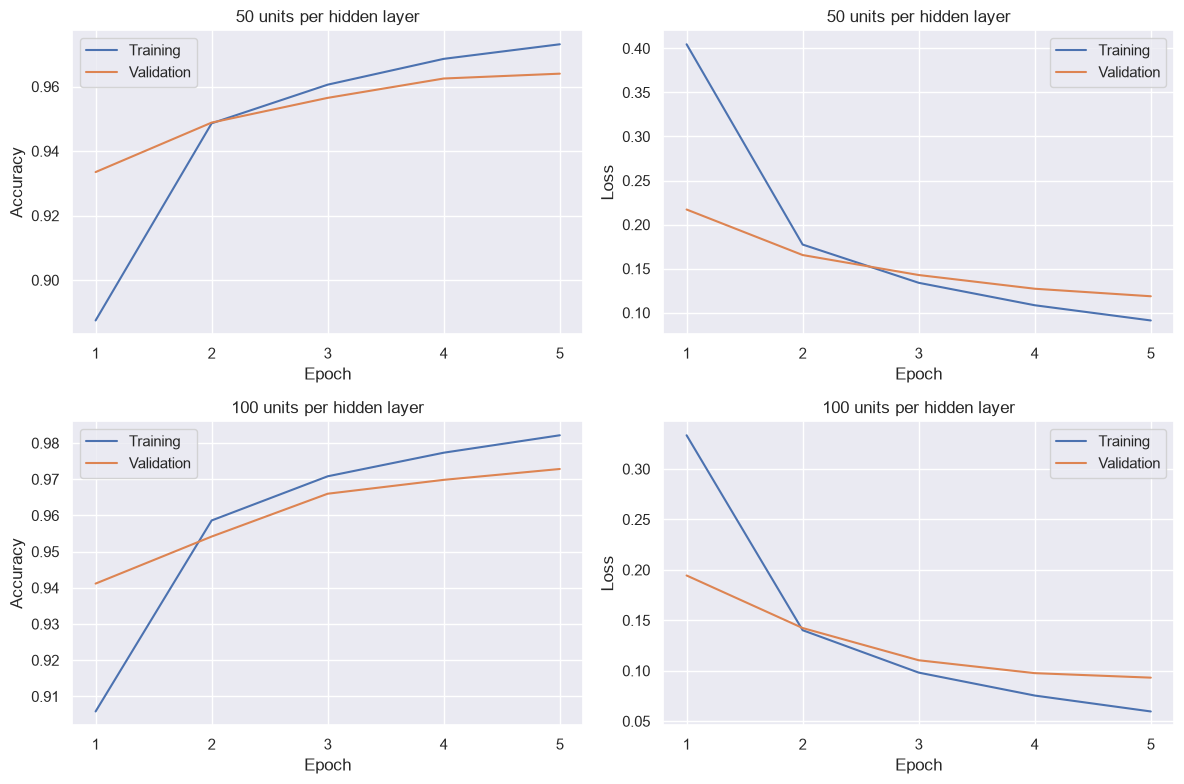

In [33]:
epochs = range(1, NUM_EPOCHS + 1)
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.plot(epochs, history_50.history['accuracy'], label='Training')
plt.plot(epochs, history_50.history['val_accuracy'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('50 units per hidden layer')
plt.xticks(epochs)
plt.legend()
plt.subplot(2, 2, 2)
plt.plot(epochs, history_50.history['loss'], label='Training')
plt.plot(epochs, history_50.history['val_loss'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('50 units per hidden layer')
plt.xticks(epochs)
plt.legend()
plt.subplot(2, 2, 3)
plt.plot(epochs, history_100.history['accuracy'], label='Training')
plt.plot(epochs, history_100.history['val_accuracy'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('100 units per hidden layer')
plt.xticks(epochs)
plt.legend()
plt.subplot(2, 2, 4)
plt.plot(epochs, history_100.history['loss'], label='Training')
plt.plot(epochs, history_100.history['val_loss'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('100 units per hidden layer')
plt.xticks(epochs)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(stage3_results_dir, 'learning_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

## 27. Select by final validation accuracy
Compare the fifth-epoch validation accuracies. Choose 100 units only when its accuracy is strictly higher; an exact tie retains 50 units. Do not select an earlier best epoch, tune extra parameters or examine the official test partition. The final five-epoch weights are retained.

In [34]:
if history_100.history['val_accuracy'][-1] > history_50.history['val_accuracy'][-1]:
    selected_model = model_100
    selected_history = history_100
    selected_hidden_units = 100
    neural_training_time = neural_100_training_time
else:
    selected_model = model_50
    selected_history = history_50
    selected_hidden_units = 50
    neural_training_time = neural_50_training_time

print('Selected hidden units per layer:', selected_hidden_units)
print('Selection: highest final validation accuracy; exact tie keeps 50 units.')
print('Total time for both NN fits (seconds): {0:.6f}'.format(neural_50_training_time + neural_100_training_time))

Selected hidden units per layer: 100
Selection: highest final validation accuracy; exact tie keeps 50 units.
Total time for both NN fits (seconds): 47.077246


## 28. Evaluate the selected model on validation only
Follow `.evaluate()` from `Untitled19.ipynb`, cells 10-11, but pass the validation partition rather than test data. Batched `.predict()` gives ten probabilities per image. **Necessary multiclass addition:** `np.argmax(..., axis=1)` converts each probability row into the most probable digit label; a binary 0.5 threshold is unsuitable.

Reuse Stage 2's Scikit-learn metrics. Accuracy is the correct fraction; macro precision, recall and F1 average the separate ten per-digit metrics equally (`zero_division=0`). No extra trial is selected using these test-free validation calculations.

In [35]:
nn_validation_loss, nn_keras_validation_accuracy = selected_model.evaluate(
    validation_inputs, validation_targets, batch_size=BATCH_SIZE, verbose=0)
neural_validation_probabilities = selected_model.predict(validation_inputs, batch_size=BATCH_SIZE, verbose=0)
assert neural_validation_probabilities.shape == (6000, 10)
assert np.isfinite(neural_validation_probabilities).all()
assert (neural_validation_probabilities >= 0).all()
assert (neural_validation_probabilities <= 1).all()
assert np.allclose(neural_validation_probabilities.sum(axis=1), 1, atol=1e-5)
neural_validation_predictions = np.argmax(neural_validation_probabilities, axis=1)
assert neural_validation_predictions.shape == (6000,)
assert np.isin(neural_validation_predictions, np.arange(10)).all()

nn_validation_accuracy = accuracy_score(validation_targets, neural_validation_predictions)
nn_validation_precision = precision_score(validation_targets, neural_validation_predictions, labels=range(10), average='macro', zero_division=0)
nn_validation_recall = recall_score(validation_targets, neural_validation_predictions, labels=range(10), average='macro', zero_division=0)
nn_validation_f1 = f1_score(validation_targets, neural_validation_predictions, labels=range(10), average='macro', zero_division=0)
assert np.isclose(nn_validation_accuracy, nn_keras_validation_accuracy, atol=1e-7)
assert np.isclose(nn_validation_loss, selected_history.history['val_loss'][-1], atol=1e-6)
assert np.isclose(nn_validation_accuracy, selected_history.history['val_accuracy'][-1], atol=1e-7)

nn_validation_metrics = {'accuracy': nn_validation_accuracy, 'macro_precision': nn_validation_precision,
                         'macro_recall': nn_validation_recall, 'macro_f1': nn_validation_f1}
print('Validation loss: {0:.6f}; accuracy: {1:.6f}'.format(nn_validation_loss, nn_validation_accuracy))
print(classification_report(validation_targets, neural_validation_predictions, labels=range(10), digits=4, zero_division=0))

Validation loss: 0.093159; accuracy: 0.972833
              precision    recall  f1-score   support

           0     0.9865    0.9898    0.9881       589
           1     0.9823    0.9881    0.9852       674
           2     0.9744    0.9711    0.9728       589
           3     0.9650    0.9550    0.9600       578
           4     0.9775    0.9692    0.9733       584
           5     0.9694    0.9566    0.9630       530
           6     0.9755    0.9803    0.9779       609
           7     0.9684    0.9823    0.9753       623
           8     0.9647    0.9632    0.9640       625
           9     0.9635    0.9683    0.9659       599

    accuracy                         0.9728      6000
   macro avg     0.9727    0.9724    0.9725      6000
weighted avg     0.9728    0.9728    0.9728      6000



## 29. Selected-model confusion matrix
Rows are actual digits, columns are predicted digits. Verify 6,000 total examples and diagonal-based accuracy. This repeats the Stage 2 ten-class adaptation of `Bank_Data_Logistic_Regression (1).ipynb`, cells 10-12 and 18-20, with the same simple Seaborn heatmap style.

In [36]:
nn_cm = confusion_matrix(validation_targets, neural_validation_predictions, labels=range(10))
nn_cm_df = pd.DataFrame(nn_cm, index=range(10), columns=range(10))
nn_cm_df.index.name = 'Actual digit'
nn_cm_df.columns.name = 'Predicted digit'
assert nn_cm.shape == (10, 10)
assert nn_cm.sum() == 6000
assert np.isclose(np.trace(nn_cm) / nn_cm.sum(), nn_validation_accuracy)
nn_cm_df

Predicted digit    0    1    2    3    4    5    6    7    8    9
Actual digit                                                     
0                583    0    1    0    1    0    2    1    1    0
1                  0  666    3    1    0    0    1    2    1    0
2                  1    2  572    2    4    0    0    3    5    0
3                  0    2    7  552    1    6    0    4    5    1
4                  0    0    1    1  566    0    3    4    0    9
5                  2    1    0    5    2  507    7    1    3    2
6                  2    1    1    0    1    3  597    0    4    0
7                  0    2    0    0    0    0    1  612    2    6
8                  3    3    2    4    1    5    1    0  602    4
9                  0    1    0    7    3    2    0    5    1  580


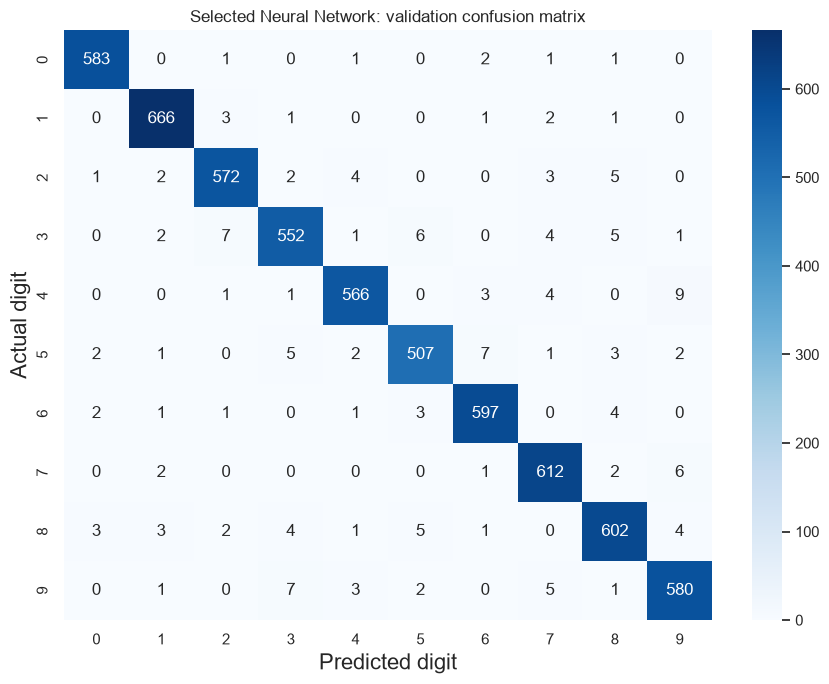

In [37]:
plt.figure(figsize=(9, 7))
seaborn.heatmap(nn_cm_df, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted digit', fontsize=16)
plt.ylabel('Actual digit', fontsize=16)
plt.title('Selected Neural Network: validation confusion matrix')
plt.tight_layout()
plt.savefig(os.path.join(stage3_results_dir, 'neural_validation_confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()

### Executed selected-model validation results
| Measure | Actual result |
|---|---:|
| Accuracy | 0.9728333333 (97.2833%) |
| Macro precision | 0.9727243935 |
| Macro recall | 0.9724000018 |
| Macro F1 | 0.9725458312 |
| Validation loss | 0.0931591764 |
| Selected-model fit time | 23.330180 seconds |
| Correct predictions | 5,837 / 6,000 |
| Incorrect predictions | 163 / 6,000 |

All probability rows are finite, lie in [0,1], and sum to approximately one. The predicted labels are valid digits 0-9. The 10 by 10 confusion matrix covers **all 6,000 validation examples**, with a diagonal sum of **5,837**. The largest off-diagonal entry is actual **4** predicted as **9** (**9** images). This matrix identifies observed errors but does not by itself establish why they occur.

Independent reconstruction from labels and predictions reproduced the entire matrix, accuracy and all three macro metrics. Keras evaluation agrees with the final recorded validation loss and accuracy. No official test examples were used.

## 30. Preliminary comparison with Logistic Regression
Read the preserved Stage 2 predictions and run record, verifying identical validation indices and labels. Recalculate their metrics to check the saved numbers. Do not refit Logistic Regression or rewrite Stage 2 artifacts.

This is a **validation-only** comparison. Neural-network fit time includes validation after each epoch; the Logistic Regression fit time excludes subsequent validation. Show the selected network's fit time and record total NN experiment time separately. Timing and this single seed/split are limited evidence, not a production benchmark. The final untouched test-set comparison belongs to Stage 4.

In [38]:
with np.load(os.path.join(project_dir, 'results', 'stage2', 'logistic_validation_predictions.npz')) as lr_outputs:
    assert np.array_equal(lr_outputs['validation_indices'], saved_validation_indices)
    assert np.array_equal(lr_outputs['actual'], validation_targets)
    lr_saved_predictions = lr_outputs['predicted']

lr_checked_metrics = {
    'accuracy': accuracy_score(validation_targets, lr_saved_predictions),
    'macro_precision': precision_score(validation_targets, lr_saved_predictions, labels=range(10), average='macro', zero_division=0),
    'macro_recall': recall_score(validation_targets, lr_saved_predictions, labels=range(10), average='macro', zero_division=0),
    'macro_f1': f1_score(validation_targets, lr_saved_predictions, labels=range(10), average='macro', zero_division=0)
}
for metric_name in lr_checked_metrics:
    assert np.isclose(lr_checked_metrics[metric_name], lr_run['validation_metrics'][metric_name], atol=1e-12, rtol=0)

validation_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Selected Neural Network'],
    'Accuracy': [lr_checked_metrics['accuracy'], nn_validation_accuracy],
    'Macro precision': [lr_checked_metrics['macro_precision'], nn_validation_precision],
    'Macro recall': [lr_checked_metrics['macro_recall'], nn_validation_recall],
    'Macro F1': [lr_checked_metrics['macro_f1'], nn_validation_f1],
    'Training time (seconds)': [lr_run['training_time_seconds'], neural_training_time]
})
validation_comparison.to_csv(os.path.join(stage3_results_dir, 'validation_model_comparison.csv'), index=False)
validation_comparison

                     Model  Accuracy  ...  Macro F1  Training time (seconds)
0      Logistic Regression  0.923667  ...  0.922606                52.845251
1  Selected Neural Network  0.972833  ...  0.972546                23.330180

[2 rows x 6 columns]


### Executed preliminary comparison
| Model | Validation accuracy | Macro precision | Macro recall | Macro F1 | Selected fit time (s) |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 92.3667% | 0.923005 | 0.922510 | 0.922606 | 52.845251 |
| Selected Neural Network | 97.2833% | 0.972724 | 0.972400 | 0.972546 | 23.330180 |

In this validation run, the selected network's accuracy is **4.9167 percentage points higher** than Logistic Regression, with **295 fewer wrong predictions** (163 versus 458). Its macro metrics are also higher. These measured results support a preliminary comparison only; the same validation partition was used to select network width, so it is not an independent final test.

Timing columns refer to different fit procedures: the network includes five epoch-validation passes, while Logistic Regression's recorded fit excludes validation prediction. The two NN experiments together used **47.077246 seconds**. A single run cannot establish a general speed ranking. Logistic Regression was not refitted or overwritten in Stage 3.

## 31. Save selected model, settings and validation artifacts
Both experiment models were saved as `neural_network_50.keras` and `neural_network_100.keras`. Save the selected final-epoch model as `neural_network.keras`, with the selection rule and exact configuration. Keep both History CSVs, trial table, curves, validation predictions/probabilities, metrics, confusion matrix and comparison.

**Required persistence addition:** native Keras `.save()`/`load_model()` was not established in the core lecture examples. `Untitled20.ipynb`, cells 8-9, supplies the familiar array save/reload pattern. The model's input contract is float32 shape (N,28,28), already divided by 255 exactly once. Flatten is included in the model; normalization is not. This differs from the 784-column input required by Logistic Regression.

Seed and native saving signatures were verified in the installed Keras sources: `keras/src/utils/rng_utils.py`, line 15; `keras/src/saving/saving_api.py`, lines 20 and 126. They are necessary additions, not claims of classroom API coverage.

In [39]:
selected_nn_path = os.path.join(models_dir, 'neural_network.keras')
selected_model.save(selected_nn_path)
selected_settings = {
    'hidden_units_per_layer': selected_hidden_units, 'hidden_layers': 2,
    'input_shape': [28, 28], 'output_units': 10, 'hidden_activation': 'relu', 'output_activation': 'softmax',
    'optimizer': 'adam', 'learning_rate': float(selected_model.optimizer.learning_rate.numpy()),
    'loss': 'sparse_categorical_crossentropy', 'epochs': NUM_EPOCHS, 'batch_size': BATCH_SIZE,
    'initialization_seed': NN_SEED,
    'selection_rule': 'Highest final epoch validation accuracy; exact tie keeps 50 units. Final epoch weights retained.',
    'split_file': 'results/stage2/split_indices.npz',
    'train_indices_sha256': lr_run['train_indices_sha256'],
    'validation_indices_sha256': lr_run['validation_indices_sha256']
}
with open(os.path.join(stage3_results_dir, 'selected_settings.json'), 'w', encoding='utf-8') as file:
    json.dump(selected_settings, file, indent=2)

nn_cm_df.to_csv(os.path.join(stage3_results_dir, 'neural_validation_confusion_matrix.csv'))
pd.DataFrame([dict(nn_validation_metrics, validation_loss=nn_validation_loss, training_time_seconds=neural_training_time)]).to_csv(
    os.path.join(stage3_results_dir, 'neural_validation_metrics.csv'), index=False)
np.savez_compressed(os.path.join(stage3_results_dir, 'neural_validation_predictions.npz'),
                    validation_indices=saved_validation_indices, actual=validation_targets,
                    predicted=neural_validation_predictions, probabilities=neural_validation_probabilities)

nn_run = {
    'stage': 'Stage 3; validation only', 'python_executable': sys.executable,
    'versions': {name: importlib.metadata.version(name) for name in ['tensorflow', 'keras', 'numpy', 'scikit-learn', 'pandas', 'matplotlib', 'seaborn']},
    'dataset_sha256': lr_run['dataset_sha256'], 'initialization_seed': NN_SEED,
    'selected_settings': selected_settings,
    'trials': nn_trial_results.to_dict(orient='records'),
    'selected_validation_metrics': nn_validation_metrics, 'selected_validation_loss': nn_validation_loss,
    'selected_training_time_seconds': neural_training_time,
    'total_nn_fit_time_seconds': neural_50_training_time + neural_100_training_time,
    'timing_scope': 'Each fit call includes five epoch-validation passes; excludes saving, later evaluation and prediction.',
    'thread_environment': {name: os.environ.get(name) for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'TF_NUM_INTRAOP_THREADS', 'TF_NUM_INTEROP_THREADS']},
    'validation_comparison': validation_comparison.to_dict(orient='records'),
    'model_files': ['models/neural_network_50.keras', 'models/neural_network_100.keras', 'models/neural_network.keras'],
    'test_partition': 'Reserved; no test images or labels used in Stage 3'
}
with open(os.path.join(models_dir, 'neural_network_preprocessing.md'), 'w', encoding='utf-8') as file:
    file.write('''# Neural Network preprocessing

The selected model is neural_network.keras. Both trial models are retained.
Use the environment and versions in results/stage3/neural_network_run.json.
Input: MNIST-style grayscale images, dark background and light strokes, raw range 0-255.
Convert pixels to NumPy float32 and divide by 255 exactly once. Retain shape (N,28,28).
Do not flatten externally: the model includes Flatten. Do not normalize twice.
Output: ten softmax probabilities in digit order 0-9. Use argmax along axis 1 for labels.
These scores are not guarantees of correctness; arbitrary photos need additional work.
Use the exact saved Stage 2 indices for validation comparison. Test data remains reserved.
''')
print('Saved selected model:', selected_nn_path)
print('Both experiments and their validation histories are retained.')

Saved selected model: ./models/neural_network.keras
Both experiments and their validation histories are retained.


## 32. Reload and verify selected-model inference
Reload the native `.keras` artifact and predict the same validation inputs. Require equal predicted labels for all 6,000 examples and numerically matching probability arrays. This verifies saving/reloading, not perfect accuracy. The chosen model is not retrained after selection.

In [40]:
loaded_nn = tf.keras.models.load_model(selected_nn_path)
reloaded_nn_probabilities = loaded_nn.predict(validation_inputs, batch_size=BATCH_SIZE, verbose=0)
reloaded_nn_predictions = np.argmax(reloaded_nn_probabilities, axis=1)
assert loaded_nn.input_shape == (None, 28, 28)
assert loaded_nn.output_shape == (None, 10)
assert np.array_equal(reloaded_nn_predictions, neural_validation_predictions)
assert np.allclose(reloaded_nn_probabilities, neural_validation_probabilities, rtol=1e-6, atol=1e-7)
assert np.isclose(accuracy_score(validation_targets, reloaded_nn_predictions), nn_validation_accuracy)

nn_run['reload_prediction_match'] = True
nn_run['reloaded_validation_images'] = int(reloaded_nn_predictions.size)
nn_run['reload_max_probability_difference'] = float(np.max(np.abs(reloaded_nn_probabilities - neural_validation_probabilities)))
nn_run['model_sha256'] = {}
for artifact_path in [model_50_path, model_100_path, selected_nn_path]:
    with open(artifact_path, 'rb') as file:
        nn_run['model_sha256'][os.path.basename(artifact_path)] = hashlib.sha256(file.read()).hexdigest()
with open(os.path.join(stage3_results_dir, 'neural_network_run.json'), 'w', encoding='utf-8') as file:
    json.dump(nn_run, file, indent=2)
print('Reloaded model matches all 6,000 original validation predictions.')
print('Maximum probability difference:', nn_run['reload_max_probability_difference'])

Reloaded model matches all 6,000 original validation predictions.
Maximum probability difference: 0.0


## Stage 3 conclusion and verification
The two classroom-style networks completed the required controlled experiment. The selected architecture is **Input(28,28) -> Flatten(784) -> Dense(100, ReLU) -> Dense(100, ReLU) -> Dense(10, Softmax)**, containing **89,610 parameters**. Its final validation accuracy is **97.2833%**, loss **0.093159**, and macro F1 **0.972546**.

| Verification | Actual evidence | Status |
|---|---|---|
| Every new Stage 3 code cell executes | All **14 new code cells** ran in order with the exact requested interpreter | Pass |
| Same split as Logistic Regression | Exact saved index arrays and hashes, image values and all targets match Stage 2 | Pass |
| Input representation | Float32 images in [0,1], retained 28 by 28 shape; labels remain integers | Pass |
| Both architectures | Two ReLU hidden layers, widths 50/50 and 100/100, ten softmax outputs; 42,310/89,610 parameters | Pass |
| Same controlled settings | Seed 42, Adam, sparse categorical cross-entropy, five epochs, batches of 100 | Pass |
| Validation-only selection | Higher final validation accuracy wins; 50-unit model would win an exact tie | Pass |
| Metrics and confusion matrix | Valid digit predictions; 6,000 entries; manually reconstructed macro metrics and matrix match | Pass |
| Native model persistence | Both trials and selected model saved as .keras; selected reload matches all 6,000 labels | Pass |
| Reloaded probabilities | Maximum absolute probability difference **0.0** | Pass |
| Preservation | Previous **64 notebook cells**, Stage 2 model/results, classroom notebooks and cache remain unchanged | Pass |
| Test-set separation | No test-array reads after the required loader; no final evaluation performed | Pass |

The verification used a fresh process: original setup/import/loading cells ran, then the exact saved Stage 2 indices and original normalization/reshape code restored its inputs. Every new Stage 3 cell executed sequentially. Existing Stage 2 fitting/saving cells were deliberately not re-executed, so its approved model and measurements were preserved. New cells consume the same preceding-stage variables and all notebook code remains syntactically valid for sequential execution from the beginning.

There were **no Stage 3 code-cell errors**. Informational TensorFlow oneDNN/CPU startup messages did not prevent training. Offline verification recorded **zero network attempts** and file guards recorded **zero attempted writes to protected earlier artifacts**. The preliminary comparison uses genuine recorded validation results. This completes Stage 3; final test-set evaluation remains unperformed.

## Stop before Stage 4: final test evaluation requires approval
Stage 3 completes the two approved neural-network experiments and preliminary **validation-only** comparison. No official MNIST test sample has been used for training, selection, prediction or evaluation.

The next stage, only after approval, will freeze final model choices and compare them on the reserved official test set. Do not change settings based on final test outcomes.